# A town and its landslides: Sarno

On 5 May 1998, after two days of rain, debris flows came down the
mountain above Sarno, in Campania, and killed 137 people there. This
notebook asks IdroGEO what it knows about the town today: its hazard and
exposure figures, the hazard at a few points, the landslides mapped in the
IFFI inventory, and who is monitoring them.

In [1]:
# pip install "ispra-idrogeo[geo]" matplotlib
from ispra_idrogeo import IdroGEO

idrogeo = IdroGEO()  # one client for the whole notebook; no account, no key

## 1. From a name to an ISTAT code

In [2]:
towns = await idrogeo.summary("iffi", "comuni")
sarno = next(t for t in towns if t["nome"] == "Sarno")
code = sarno["pro_com"]
code

65135

## 2. How exposed is the town?

`pir` gives hazard and exposure: how much land, how many residents,
buildings and cultural heritage sit in each landslide (P1–P4, AA) and flood
(P1–P3) hazard class.

In [3]:
risk = await idrogeo.summary("pir", "comuni", code)
print(f"{risk['nome']}: {risk['pop_res021']:,} residents, {risk['ar_kmq']:.1f} km²")
print(f"land in landslide hazard P3+P4: {risk['ar_frp3p4p']:.1f}%")
print(f"residents there: {risk['pop_fr_p3'] + risk['pop_fr_p4']:,} ({risk['popfrp3p4p']:.1f}%)")
print(f"residents in flood hazard P2: {risk['pop_idr_p2']:,} ({risk['popidp2_p']:.1f}%)")

Sarno: 30,652 residents, 40.0 km²
land in landslide hazard P3+P4: 43.4%
residents there: 1,109 (3.6%)
residents in flood hazard P2: 872 (2.8%)


## 3. The hazard at a point

One request to IdroGEO's public map service: the PAI landslide class, the
flood scenarios, the municipality and the slope.

In [4]:
points = {
    "town centre": (40.8130, 14.6110),
    "foot of the mountain": (40.8290, 14.6170),
    "on the slope": (40.8380, 14.6300),
}
for name, (lat, lon) in points.items():
    here = await idrogeo.hazard_at(lat, lon)
    landslide, flood = here.landslide or "-", here.flood or "-"
    print(f"{name:22} landslide {landslide:3} flood {flood:3} slope {here.slope_deg}°")

town centre            landslide -   flood -   slope 0.6°


foot of the mountain   landslide P4  flood -   slope 12.3°


on the slope           landslide P4  flood -   slope 29.5°


## 4. The landslides mapped in Sarno

The polygons come from the Campania file (31 MB, downloaded once and then
revalidated with a `304`). Each one is labelled with its type of movement.

In [5]:
from ispra_idrogeo import opendata
from ispra_idrogeo.geo import add_labels, read

folder = await idrogeo.fetch(opendata("frane_poly", "campania"))
labels = await idrogeo.code_labels(["tipo_movim"])
campania = add_labels(read(folder), labels)
town = campania[campania["comune"] == code]
town["tipo_movim_label"].value_counts()

tipo_movim_label
rapid debris flow                 25
rotational/translational slide    13
Name: count, dtype: int64

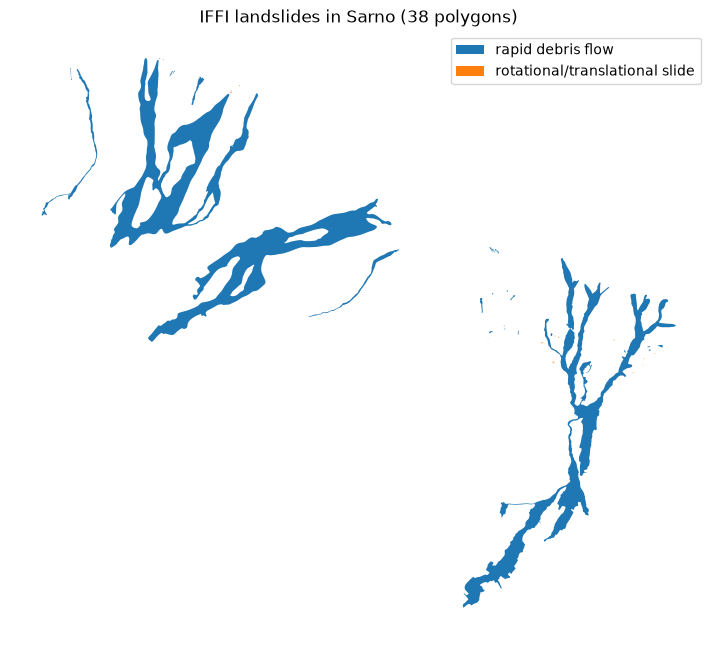

In [6]:
import matplotlib.pyplot as plt

ax = town.plot(column="tipo_movim_label", legend=True, figsize=(9, 8), cmap="tab10")
ax.set_title(f"IFFI landslides in Sarno ({len(town)} polygons)")
ax.set_axis_off()
plt.show()

## 5. Landslides near a point

The distance is measured to each landslide's real outline.

In [7]:
near = await idrogeo.landslides_near(40.8380, 14.6300, radius_m=1000)
for f in near[:5]:
    print(f["id_frana"], f["nome_tipo"], f["nome_com"], f"{f['distance_m']:.0f} m")

0640689600 Colamento rapido Quindici 398 m
0650005900 Colamento rapido Sarno 714 m
0653347200 Scivolamento rotazionale/traslativo Sarno 779 m
0650006400 Colamento rapido Sarno 845 m
0652959100 Colamento rapido Sarno 871 m


## 6. Who is monitoring the area?

In [8]:
from ispra_idrogeo import decode, site_filter

sites = await idrogeo.sites(site_filter(province=65))  # the province of Salerno
site_labels = await idrogeo.code_labels(["stato_monitoraggio", "strumentazione"])
for site in sites[:5]:
    s = decode(site, site_labels)
    instruments = ", ".join(s["strumentazione_label"] or [])
    print(s["uid"], s["localita"], "-", s["stato_monitoraggio_label"], "-", instruments)

SICAM003 Centola - active - inclinometer, strain gauge, topographic monitoring, hydrometeorological monitoring
SICAM004 Sarno - active - hydrometeorological monitoring, TDR echometer


In [9]:
await idrogeo.aclose()

Source: ISPRA — IdroGEO (CC BY 4.0). Credit it when you publish anything
derived from these data.